# Sales Prediction from Advertising Budgets

**Goal:** Predict product **Sales** from TV, Radio and Newspaper advertising spend.

**Dataset:** `Advertising.csv` – 200 rows, 3 features

**Approach:** EDA → IQR outlier check → scaling (StandardScaler for TV/Radio, RobustScaler for Newspaper because of outliers) → correlation heatmap → Linear Regression → MAE / RMSE / R².

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load the data

In [2]:
df=pd.read_csv('../data/Advertising.csv')

In [3]:
df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


## Exploratory data analysis

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [5]:
df.describe()

,Unnamed: 0,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [6]:
df.shape

(200, 5)

In [7]:
df.isnull().sum()

Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.drop('Unnamed: 0', axis=1, inplace=True)

In [10]:
df

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5


## Outlier detection (IQR)

In [11]:
for col in df:
    Q1 = np.percentile(df[col], 25)
    Q3 = np.percentile(df[col], 75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers_count = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {outliers_count} outliers (range: {lower:.2f} to {upper:.2f})")

TV: 0 outliers (range: -142.30 to 435.50)
Radio: 0 outliers (range: -29.85 to 76.35)
Newspaper: 2 outliers (range: -35.78 to 93.62)
Sales: 0 outliers (range: -0.16 to 27.94)


## Feature distributions

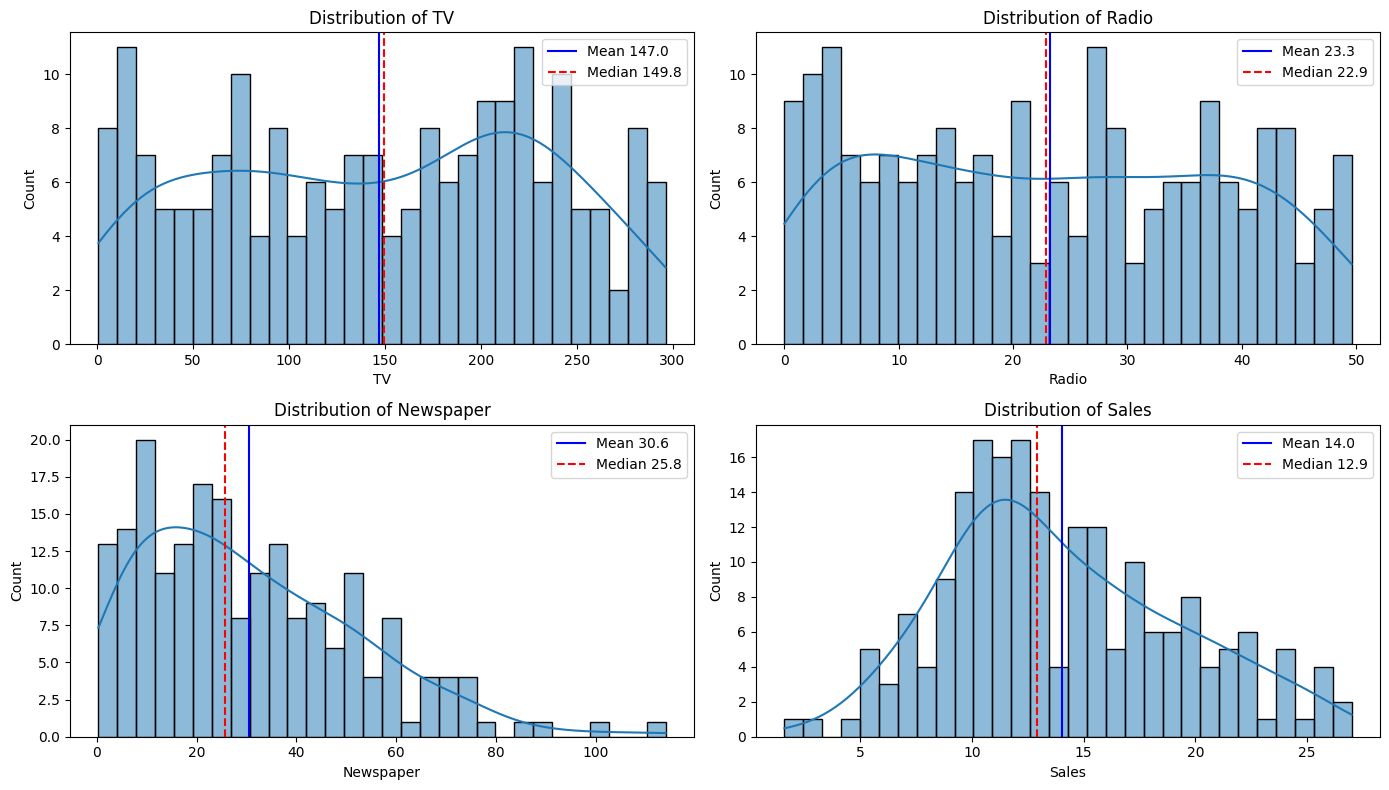

In [12]:
cols = df.columns         
n_cols = 2
n_rows = (len(cols) + n_cols - 1) // n_cols   # = 2

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows * 4))
axes = axes.flatten()   # 2D ---> 1D

for i, col in enumerate(cols):
    sns.histplot(x=df[col], ax=axes[i], kde=True, bins=30)

    mean_val   = df[col].mean()
    median_val = df[col].median()

    axes[i].axvline(mean_val,   color='blue', linestyle='-',  label=f'Mean {mean_val:.1f}')
    axes[i].axvline(median_val, color='red',  linestyle='--', label=f'Median {median_val:.1f}')

    axes[i].set_title(f"Distribution of {col}")
    axes[i].legend()


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [13]:
from sklearn.preprocessing import StandardScaler, RobustScaler

## Feature scaling

In [14]:
std_scaler = StandardScaler()
rob_scaler = RobustScaler()

df[['TV', 'Radio']] = std_scaler.fit_transform(df[['TV', 'Radio']])
df[['Newspaper']]   = rob_scaler.fit_transform(df[['Newspaper']])

df.head()

,TV,Radio,Newspaper,Sales
0,0.969852,0.981522,1.343122,22.1
1,-1.197376,1.082808,0.598145,10.4
2,-1.516155,1.528463,1.346213,9.3
3,0.052050,1.217855,1.012365,18.5
4,0.394182,-0.841614,1.009274,12.9


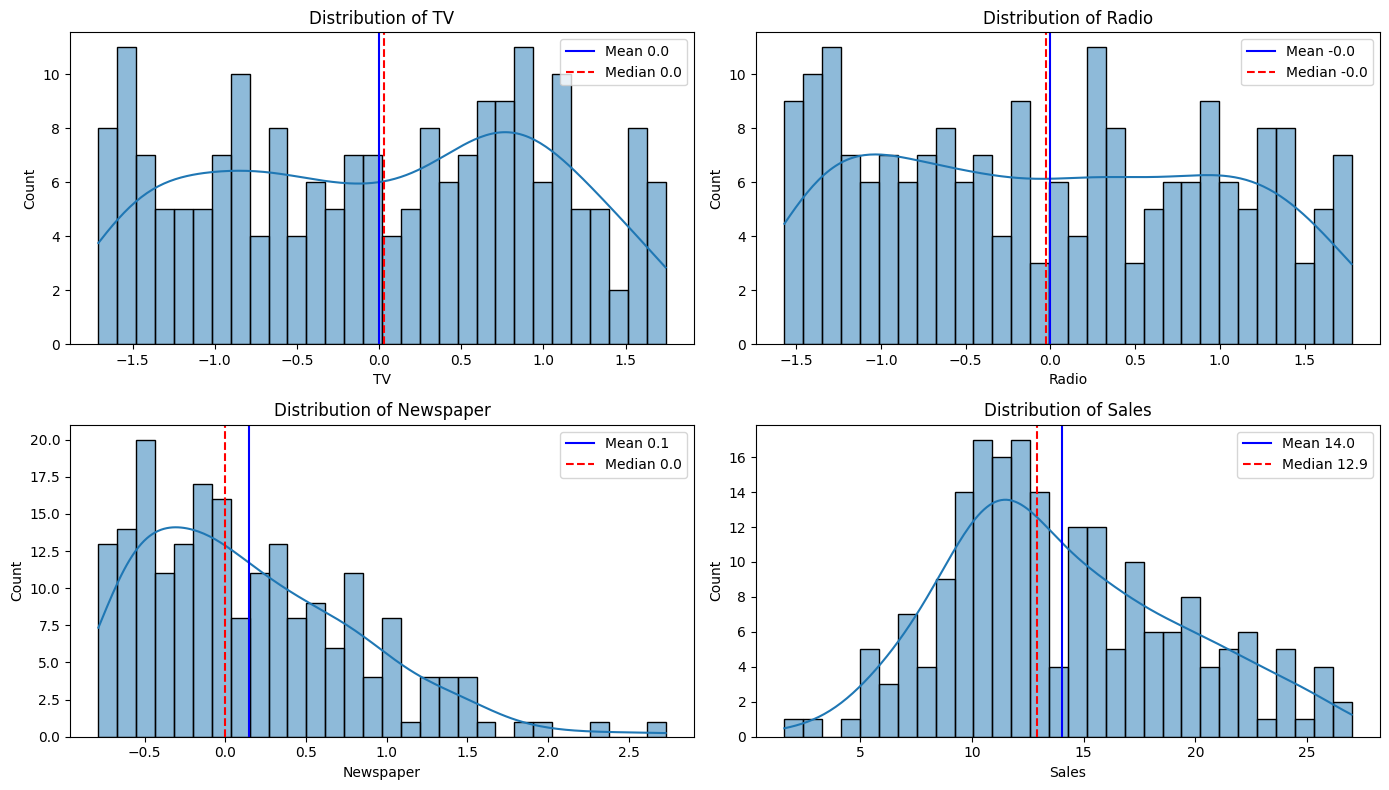

In [15]:
cols = df.columns         
n_cols = 2
n_rows = (len(cols) + n_cols - 1) // n_cols   # = 2

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows * 4))
axes = axes.flatten()   # 2D ---> 1D

for i, col in enumerate(cols):
    sns.histplot(x=df[col], ax=axes[i], kde=True, bins=30)

    mean_val   = df[col].mean()
    median_val = df[col].median()

    axes[i].axvline(mean_val,   color='blue', linestyle='-',  label=f'Mean {mean_val:.1f}')
    axes[i].axvline(median_val, color='red',  linestyle='--', label=f'Median {median_val:.1f}')

    axes[i].set_title(f"Distribution of {col}")
    axes[i].legend()


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Correlation analysis

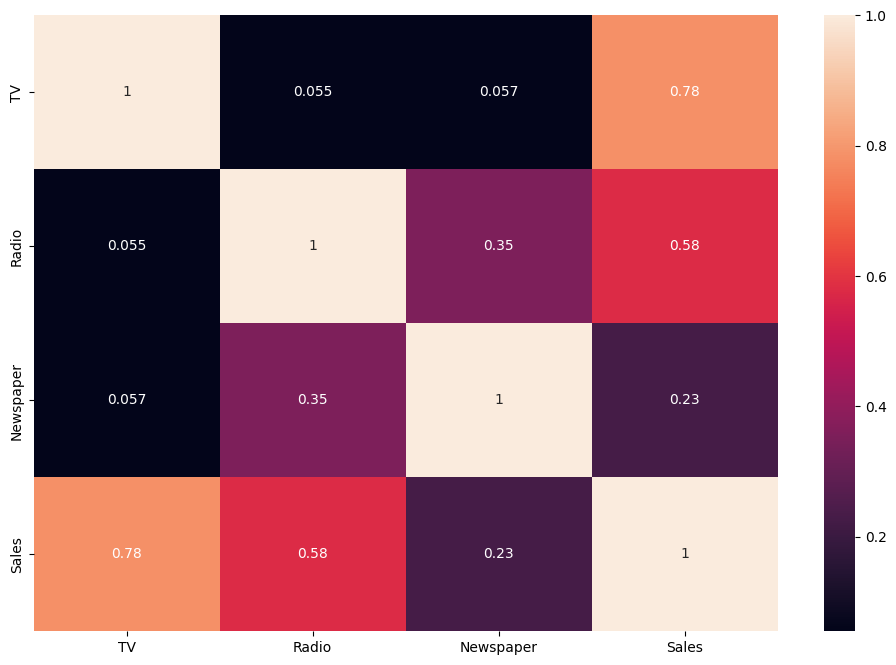

In [16]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),annot=True)
plt.show()

In [17]:
X = df.drop('Sales', axis=1)
y = df['Sales']


## Train / test split

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


## Model training

In [19]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


## Evaluation

In [20]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_pred = model.predict(X_test)

print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²  :", r2_score(y_test, y_pred))


MAE : 1.4607567168117601
MSE : 3.174097353976105
RMSE: 1.7815996615334504
R²  : 0.899438024100912


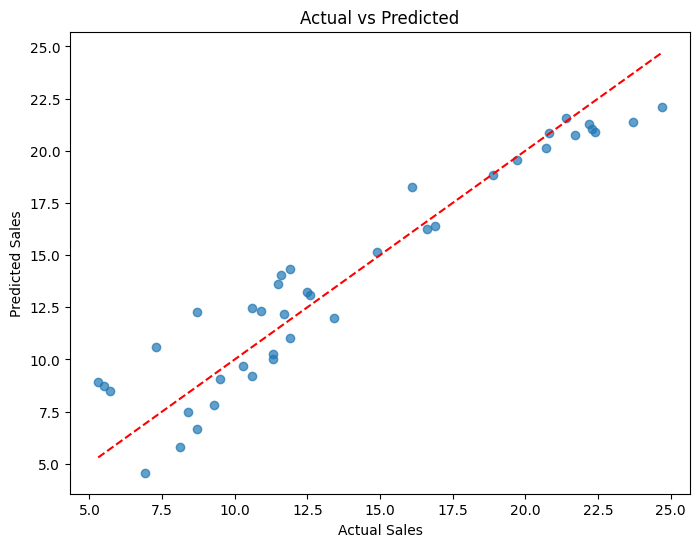

In [21]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted")
plt.show()

## Results & conclusion

| Metric | Value |
|---|---|
| MAE | 1.46 |
| RMSE | 1.78 |
| R² | **0.90** |

* TV and Radio budgets have the strongest correlation with Sales; Newspaper adds very little.
* A plain linear model already explains ~90% of the variance in sales.